In [1]:
import pandas as pd
import numpy as np
from parsivar import Tokenizer, Normalizer
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
# from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
from sklearn.linear_model import LogisticRegression
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_validate, StratifiedKFold

In [2]:
df = pd.read_csv("Snappfood - Sentiment Analysis.csv", delimiter="\t")
df = df[["comment", "label"]]
df.head()

,comment,label
0,واقعا حیف وقت که بنویسم سرویس دهیتون شده افتضاح,SAD
1,قرار بود ۱ ساعته برسه ولی نیم ساعت زودتر از مو...,HAPPY
2,قیمت این مدل اصلا با کیفیتش سازگاری نداره، فقط...,SAD
3,عالللی بود همه چه درست و به اندازه و کیفیت خوب...,HAPPY
4,شیرینی وانیلی فقط یک مدل بود.,HAPPY


In [14]:
for i in df['comment'].iloc[np.where(df['label'] == 'HAPPY')][:3].values:
    print(i)

قرار بود ۱ ساعته برسه ولی نیم ساعت زودتر از موقع رسید، شما ببین چقدرررررررررررر پلاک خفنههههه، من سالهاست مشتریشونم و سالهاست مزه بهشت میده غذاشون
عالللی بود همه چه درست و به اندازه و کیفیت خوب، امیداورم همیشه کیفیتتون خوب باشه ما مشتری همیشگی بشیم
شیرینی وانیلی فقط یک مدل بود.


In [15]:
for i in df['comment'].iloc[np.where(df['label'] == 'SAD')][:3].values:
    print(i)

واقعا حیف وقت که بنویسم سرویس دهیتون شده افتضاح
قیمت این مدل اصلا با کیفیتش سازگاری نداره، فقط ظاهر فریبنده داره، پرش میکنن کالباس و قارچ
بدترین پیتزایی که تا به حال خورده بودم


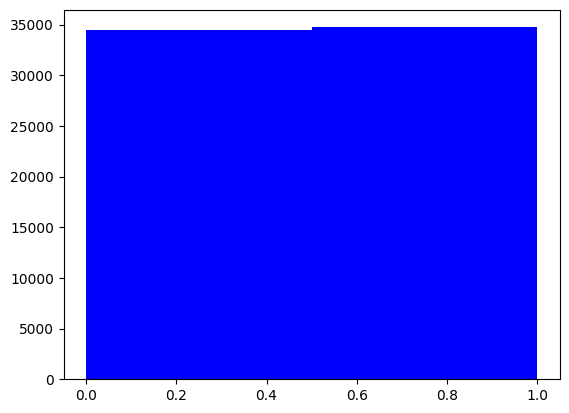

In [93]:
plt.hist(df['label'],bins=2, color='blue')

In [17]:
normalizer = Normalizer()
tokenizer = Tokenizer()

In [18]:
delete_list = '!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~،؟1234567890'

def text_correction(text):
    n_text = normalizer.normalize(text)
    words = "".join([char for char in n_text if char not in delete_list])
    c_text = re.sub(r"(.)\1{2,}", r"\1", words)
    return c_text.strip().replace("  ", " ")

In [19]:
text_correction("سلااااااام، چه طــــــــوررری؟")
df["comment"] = df["comment"].apply(text_correction)

In [20]:
df['label'] = df['label'].map({'SAD':0,'HAPPY':1})

In [21]:
df.drop(df[df["comment"].duplicated()].index, inplace=True)

In [22]:
df.head(5)

,comment,label
0,واقعا حیف وقت که بنویسم سرویس دهیتون‌شده‌افتضاح,0
1,قرار‌بود ساعته برسه ولی نیم ساعت زودتر از موقع...,1
2,قیمت این مدل اصلا با کیفیتش سازگاری نداره فقط ...,0
3,عالی‌بود همه چه درست و به اندازه و کیفیت خوب ا...,1
4,شیرینی وانیلی فقط یک مدل‌بود,1


In [23]:
stop_words = pd.read_csv("snapfood_stopwords_light.csv")['stopword'].to_list()

In [25]:
stop_words[:10]

['بود', 'به', 'که', 'از', 'هم', 'با', 'ولی', 'شده', 'در', 'این']

In [26]:
vectorizer = TfidfVectorizer(ngram_range=(1,4), max_features=120000, stop_words=stop_words)
# v = vectorizer.fit_transform(df['comment'].iloc[np.where(df['label'] == 1)[0]])
vectorizer.fit(df['comment'])

,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.","['بود', 'به', ...]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",120000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'word'


In [27]:
vec_def = pd.DataFrame(vectorizer.get_feature_names_out())
# vec_def.to_csv("vec.csv", index=False)

In [89]:
vec_def[vec_def[0].str.count(" ") > 2].values[:15]

array([['آب معدنی سفارش داده'],
       ['آبروم جلو مهمونام رفت'],
       ['آبروم جلوی مهمونام رفت'],
       ['آخرین بار سفارش دادم'],
       ['آخرین بار سفارش میدم'],
       ['آخرین بارم رستوران غذا'],
       ['آخرین بارم سفارش دادم'],
       ['آخرین باری رستوران سفارش'],
       ['آخرین باری رستوران غذا'],
       ['آخرین باری سفارش دادم'],
       ['آخرین باری سفارش میدم'],
       ['آرزوی موفقیت روز افزون'],
       ['آلفردو فرایز خیلی خوب'],
       ['آماده سازی بسیار طولانی'],
       ['آماده سازی تحویل غذا']], dtype=object)

In [95]:
x_train , x_test , y_train, y_test = train_test_split(df['comment'], df['label'], train_size=0.95, random_state=42, stratify=df['label'])

In [96]:
v_x_train = vectorizer.transform(x_train)
v_x_test = vectorizer.transform(x_test)

In [97]:
len(y_train), len(y_test)

(65777, 3462)

In [162]:
nb = MultinomialNB(alpha=1.0)
nb.fit(v_x_train,y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[32784.,32993.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.7 ,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 120000)","[[0.99,0.33,0.95,...,0.22,0.61,1.79], [0. ,8.14,0. ,...,0.53,0.34,1.89]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 120000)","[[-11.78,-12.19,-11.8 ,...,-12.28,-11.99,-11.45], [-12.41,-10.19,-12.41,...,-11.98,-12.11,-11.34]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,120000


In [163]:
skf = StratifiedKFold(n_splits=5)
c_v = cross_validate(
    estimator=nb,
    cv=skf,
    n_jobs=-1,
    scoring='accuracy',
    X=v_x_train,
    y=y_train,
)

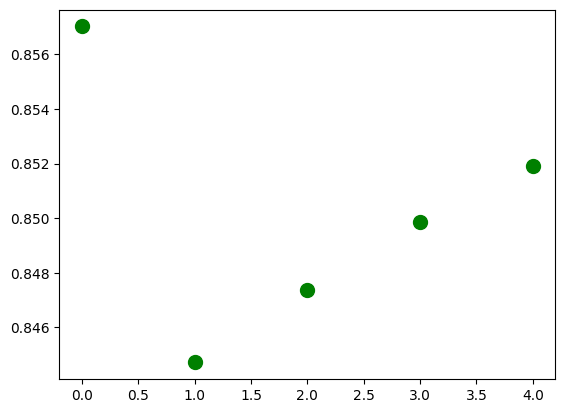

In [164]:
plt.scatter(np.arange(5),c_v['test_score'], s=100, color='green')

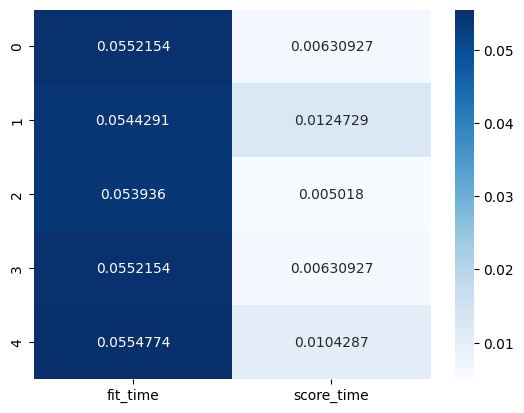

In [165]:
timing = pd.DataFrame(np.c_[c_v['fit_time'] ,c_v['score_time']], columns=['fit_time', 'score_time'])
sns.heatmap(timing, annot=True, fmt="g", cmap="Blues")

In [166]:
y_pred = nb.predict(v_x_train)
print(classification_report(y_train, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.95      0.90     32784
           1       0.95      0.84      0.89     32993

    accuracy                           0.89     65777
   macro avg       0.90      0.89      0.89     65777
weighted avg       0.90      0.89      0.89     65777



In [167]:
y_pred = nb.predict(v_x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.92      0.85      1725
           1       0.90      0.78      0.83      1737

    accuracy                           0.85      3462
   macro avg       0.85      0.85      0.84      3462
weighted avg       0.85      0.85      0.84      3462



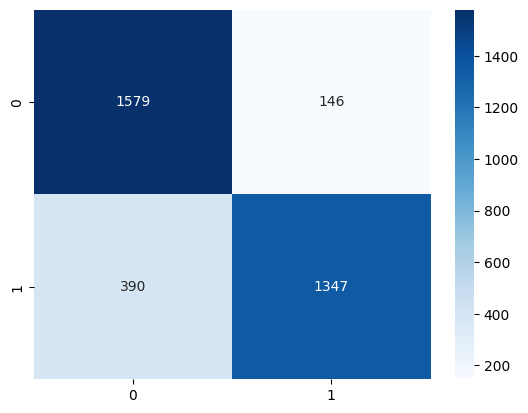

In [168]:
sns.heatmap(confusion_matrix(y_test, y_pred), cmap="Blues", annot=True, fmt="g")

In [169]:
model = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    l1_ratio=0.5,
)

model.fit(v_x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.5
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"C C: float, default=1.0Inverse of regularization streng

In [170]:
y_pred = nb.predict(v_x_train)
print(classification_report(y_train, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.95      0.90     32784
           1       0.95      0.84      0.89     32993

    accuracy                           0.89     65777
   macro avg       0.90      0.89      0.89     65777
weighted avg       0.90      0.89      0.89     65777



In [171]:
y_pred = nb.predict(v_x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.92      0.85      1725
           1       0.90      0.78      0.83      1737

    accuracy                           0.85      3462
   macro avg       0.85      0.85      0.84      3462
weighted avg       0.85      0.85      0.84      3462



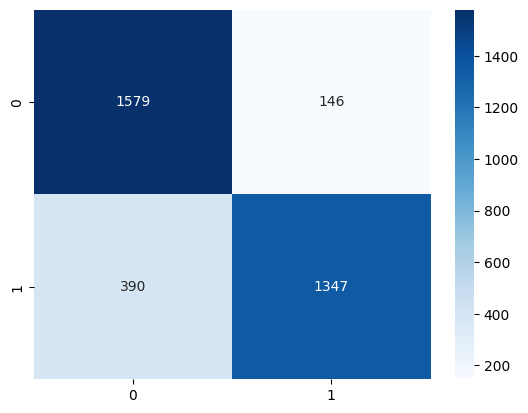

In [172]:
sns.heatmap(confusion_matrix(y_test, y_pred), cmap="Blues", annot=True, fmt="g")

In [173]:
h_wrong_pred = np.where((y_test != y_pred) & (y_test == 1))[0]
s_wrong_pred = np.where((y_test != y_pred) & (y_test == 0))[0]

In [174]:
len(h_wrong_pred) , len(s_wrong_pred)

(390, 146)

In [182]:
for i in x_test.iloc[h_wrong_pred[:10]].values:
    print(f"< {i} >")

< آخه یعنی چی قیمتها اینقدر بالا برده‌شده‌ >
< یک نوشابه کمتر ارسال‌شده‌بود >
< وقتی فالوده رسید تمام آب آن خالی‌شده‌بود >
< روغن سبوس برنج رو مارک دیگه‌ای که اختلاف قیمت هم داشت فرستادن >
< سلام بخشهایی از نان‌ها همیشه خمیر و بی‌استفاده است >
< فروشگاه محترم یک عدد شیر تحویل نداده است و تماس گرفتم و خواستند بفرستند گفتم چون مشتری هستم الان یک شیر نفرستند رو حساب بعدی برام بفرستند امیدوارم خوش حساب باشند با تشکر ا >
< نان سیر سرد‌بود سس پاستا پنه خیلی کم‌بود وغذا سرد بود >
< من همیشه بره سفارش میدم خوب هست متاسفانه نون ساندویچ مونده‌بود و تازه نبود کاشکی ساندویچ از روز قبل مونده رو ارسال نکنید تا اعتماد مشتریان رو از دست ندید >
< با اینکه اکثرا از کوبیده‌ها خوشم نمیاد ولی کوبیده‌ی سالم و معده‌فرندلی‌ای بود >
< حجم سیب‌زمینی و برگراش کم بود >


In [183]:
for i in x_test.iloc[s_wrong_pred[:10]].values:
    print(f"< {i} >")

< نذری سره کوچمون خیلی خوشمزه‌تر‌بود گوشتم داشت >
< به نظرم اگر هم پنیر رو با آب مخلوط می‌کنید مقدار کم‌تر بریزید تا برگر از هم نپاشه >
< بدک نبود ولی خوشمزه هم نبود >
< غذا خوشمزه نبود اما انتقاد اصلی من بابت گرفتن مالیات هست که گرفتنش ممنوع هست و من بسیار گله مند هستم بابت این موضوع >
< آش دوغ هیچ مخلفاتی نداشت و حبوبات آش رشته هم نپخته‌بود کیفیت غذا بسیار پایین‌بود اما ممنونم از اسنپ فود که بسیار سریع و زودتر از موعد رسید >
< Bi keyfiat heyf az pul vaghean heyf >
< سالاد خیلی بی‌سلیقه و بی‌مزه بود >
< مثل همیشه بی‌کیفیت >
< از نظر کمیت خیلی پر حجم‌بود ولی از نظر کیفیت چندان چنگی به دل نمیزد البته به نسبت قیمت خدایی خوب بود >
< با اینکه در قسمت توضیحات نوشته‌بودم باز هم کیک تکون خورده به دستم رسیده و سالم نیست >
